In [ ]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import pandas as pd
from scipy.stats import spearmanr
sys.path.append('../../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = "glpk"

In [2]:
with open('../../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data4 = pickle.load(pickle_file)
    all_total_nutrient_count4 = data4['all_total_nutrient_count']
    all_total_intake4 = data4['all_total_intake']
    all_growth_rate4 = data4['all_growth_rate']
    all_random_medium4 = data4['all_random_medium']
    all_met_flux4 = data4['all_met_flux']
    del data4

In [3]:
with open('../../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

In [4]:
from dataclasses import dataclass

@dataclass
class Sample:
    E: np.ndarray      # shape (n,)
    Y: float
    M: int

with open('../../../FBAsolution/all_samples_wo_normalize.pkl', 'rb') as f:
    data = pickle.load(f)
    samples = data['samples1']
    samples2 = data['samples2']
    samples3 = data['samples3']
    samples4 = data['samples4']
total_samples = samples + samples2 + samples3 + samples4

In [ ]:
def node_detailed_proteome_cost(met_flux, node_id, cluster_nodes):
        
    grouped_rec = [rec for rec in cluster_nodes[node_id] if 'EX_' not in rec]
    #grouped_flux = {rec: value for rec, value in met_flux if rec+'_fwd' in grouped_rec  or rec+'_bwd' in grouped_rec}

    grouped_flux = {rec: value for rec, value in met_flux if (rec+'_fwd' in grouped_rec and value > 0) or (rec+'_bwd' in grouped_rec and value < 0)}

    node_detailed = []

    for rec, flux in grouped_flux.items():
        proteome_cost = abs(flux)
        node_detailed.append((rec, node_id, proteome_cost))

    return node_detailed

def graph_detailed_proteome_cost(met_flux, cluster_nodes):
    graph_detailed_proteome_cost = []

    for node_id in range(20):
        temp = node_detailed_proteome_cost(met_flux, node_id, cluster_nodes)
        graph_detailed_proteome_cost.append(temp)

    return graph_detailed_proteome_cost

from itertools import chain
def build_reaction_flux_df(all_met_flux_species_list, cluster_nodes):
    n_species = len(all_met_flux_species_list)
    species_indices = range(n_species)

    # {(reaction, sector_idx): {sp_idx: flux}}
    reaction_flux = {}

    for sp_idx in species_indices:
        res = graph_detailed_proteome_cost(all_met_flux_species_list[sp_idx], cluster_nodes)
        if not res:
            continue
        if isinstance(res[0], tuple):
            triplets = res
        else:
            triplets = list(chain.from_iterable(res))

        total_flux = sum(
            flux
            for rxn, sector_idx, flux in triplets
        )

        for rxn, sector_idx, flux in triplets:
            reaction_fraction = flux / total_flux if total_flux != 0 else 0
            key = (rxn, sector_idx)
            if key not in reaction_flux:
                reaction_flux[key] = {}
            reaction_flux[key][sp_idx] = reaction_fraction #flux

    rows = []
    for (rxn, sector_idx), sp_flux in reaction_flux.items():
        flux_list = [sp_flux.get(sp_idx, 0) for sp_idx in species_indices]
        rows.append({
            "reaction": rxn,
            "Cluster": sector_idx,
            "flux_list": flux_list,
        })

    df_reaction_flux = pd.DataFrame(rows)
    return df_reaction_flux

df_flux = build_reaction_flux_df(all_met_flux4[0], cluster_nodes)
combined_df = df_flux[df_flux["Cluster"] != 19].reset_index(drop=True)

In [6]:
flux_matrix = np.vstack(combined_df["flux_list"].tolist())
gr = all_growth_rate4[0]
od_env = np.array(gr)

combined_df["Corr"] = [spearmanr(row, od_env)[0] for row in flux_matrix] 


cluster_corrs = []

for cluster_id, indices in combined_df.groupby("Cluster").indices.items():

    expr_sum = flux_matrix[indices].sum(axis=0)

    if np.all(expr_sum == 0) or np.std(expr_sum) == 0:
        corr = 0.0 
    else:
        corr, _ = spearmanr(expr_sum, od_env)
    cluster_corrs.append(corr)

obs_mean = np.nanmean(np.abs(cluster_corrs))
obs_var = combined_df.groupby("Cluster")["Corr"].var().mean()

n_perm = 10000
random_means = []
random_vars = []

original_clusters = combined_df["Cluster"].values
n_samples = len(combined_df)

for _ in range(n_perm):
    shuffled_clusters = np.random.permutation(original_clusters)

    group_mapper = pd.Series(shuffled_clusters, index=combined_df.index)
    
    def calc_shuffled_corr(indices):
        group_sum = flux_matrix[indices].sum(axis=0)
        if np.std(group_sum) == 0:
            return 0.0
        return abs(spearmanr(group_sum, od_env)[0])

    grouped_indices = group_mapper.groupby(group_mapper).indices
    
    current_perm_corrs = [calc_shuffled_corr(idx) for idx in grouped_indices.values()]
    random_means.append(np.nanmean(current_perm_corrs))
    
    current_vars = combined_df["Corr"].groupby(group_mapper).var()
    random_vars.append(current_vars.mean())

Observed Mean: 0.2812, p-value: 0.0001, z-score: 6.30


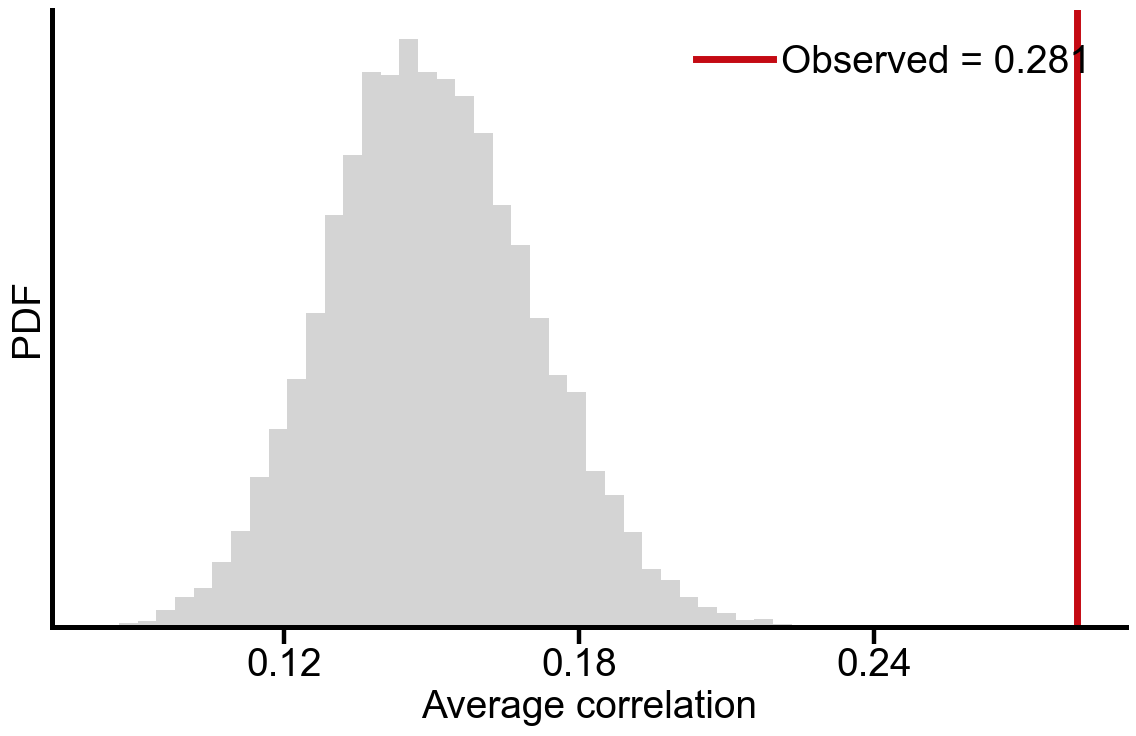

In [7]:
from matplotlib.ticker import MaxNLocator
set_panel_style(scale=4)

hist_color = "#D0D0D0"   # light gray
mean_line  = "#C40A13"   # deep red
var_line   = "#2F5597"   # deep blue

p_mean = (np.sum(np.array(random_means) >= obs_mean) + 1) / (n_perm + 1)
p_var  = (np.sum(np.array(random_vars)  <= obs_var)  + 1) / (n_perm + 1)
z_mean = (obs_mean - np.mean(random_means)) / np.std(random_means)
print(f"Observed Mean: {obs_mean:.4f}, p-value: {p_mean:.4f}, z-score: {z_mean:.2f}")

# ---------------- Figure 1: mean ----------------
fig, ax = plt.subplots(figsize=(12, 8))

ax.hist(random_means, bins=40, color=hist_color, alpha=0.9, edgecolor="none")
ax.axvline(obs_mean, color=mean_line, linewidth=5,
           label=rf"Observed = {obs_mean:.3f}")

ax.set_xlabel("Average correlation")
ax.set_ylabel("PDF")
ax.legend(frameon=False, handletextpad=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="y", left=False, labelleft=False)

ax.xaxis.set_major_locator(MaxNLocator(nbins=4))

plt.tight_layout()
plt.show()
